**Name : Aramina P. Galario**

**Section: DS4A**

# Wonders of the World: Image Classification with Pretrained `torchvision` Models

**Goal:** curate the *Wonders of the World* image dataset, load it with a custom PyTorch `Dataset`/`DataLoader`, run five pretrained `torchvision` models on CUDA, and compare them with accuracy, precision, recall and F1-score.

**Method (important):** the pretrained models were trained on ImageNet's 1,000 classes, which do not match our 12 landmark classes. So each model is used as a **frozen feature extractor** (pretrained backbone, final classification layer removed) and a small **linear head (12 outputs)** is trained on top of the extracted features using the training split. Every model is then evaluated on the same held-out **test split**. This keeps the comparison fair: the only thing that differs between runs is the backbone.

**Models compared:** VGG16, ResNet50, DenseNet121, EfficientNet-B0, ViT-B/16.

## 1. Setup and CUDA check

In [1]:
import os, time, zipfile, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

assert torch.cuda.is_available(), "CUDA GPU not found. In Colab: Runtime > Change runtime type > GPU."
device = torch.device("cuda")
print("PyTorch :", torch.__version__)
print("GPU     :", torch.cuda.get_device_name(0))

PyTorch : 2.11.0+cu128
GPU     : NVIDIA GeForce RTX 5050


## 2. Configuration

Set `ZIP_PATH` to wherever the zip lives (in Colab, upload it to the file panel or mount Drive). Set `NUM_WORKERS = 0` if you are on Windows and DataLoader workers hang.

In [2]:
ZIP_PATH    = "WondersOfTheWorld_Dataset.zip"   # <- change if needed
EXTRACT_DIR = Path("wonders_data")
OUT_DIR     = Path("results"); OUT_DIR.mkdir(exist_ok=True)

BATCH_SIZE  = 64
NUM_WORKERS = 0

# Stratified split: 70% train / 15% val / 15% test
VAL_FRAC, TEST_FRAC = 0.15, 0.15

## 3. Curate and organize the dataset

The zip contains one folder per class plus `wonders_of_world_images.csv` (`folder_name`, `filename`). We extract it, verify every listed file exists and can be opened, encode the labels, and build stratified train/val/test splits.

In [3]:
if not EXTRACT_DIR.exists():
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(EXTRACT_DIR)

csv_path = next(EXTRACT_DIR.rglob("wonders_of_world_images.csv"))
df = pd.read_csv(csv_path)
df.columns = [c.strip() for c in df.columns]

# Locate the folder that actually contains the class sub-folders
first = df.iloc[0]
sample = next(EXTRACT_DIR.rglob(first.filename))
IMG_ROOT = sample.parent.parent
print("CSV      :", csv_path)
print("Image root:", IMG_ROOT)

# --- integrity check: every file exists and decodes ---
bad = []
for r in df.itertuples():
    p = IMG_ROOT / r.folder_name / r.filename
    try:
        with Image.open(p) as im:
            im.verify()
    except Exception as e:
        bad.append((str(p), repr(e)[:60]))
print(f"Images listed: {len(df)} | unreadable/missing: {len(bad)}")
if bad:
    bad_paths = {b[0] for b in bad}
    df = df[[str(IMG_ROOT / r.folder_name / r.filename) not in bad_paths for r in df.itertuples()]].reset_index(drop=True)

# --- label encoding ---
classes = sorted(df.folder_name.unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
df["label"] = df.folder_name.map(class_to_idx)
NUM_CLASSES = len(classes)
print(f"{NUM_CLASSES} classes:", classes)

CSV      : wonders_data\wonders_of_world_images.csv
Image root: wonders_data\Wonders of World\Wonders of World
Images listed: 3846 | unreadable/missing: 0
12 classes: ['burj_khalifa', 'chichen_itza', 'christ_the_reedemer', 'eiffel_tower', 'great_wall_of_china', 'machu_pichu', 'pyramids_of_giza', 'roman_colosseum', 'statue_of_liberty', 'stonehenge', 'taj_mahal', 'venezuela_angel_falls']


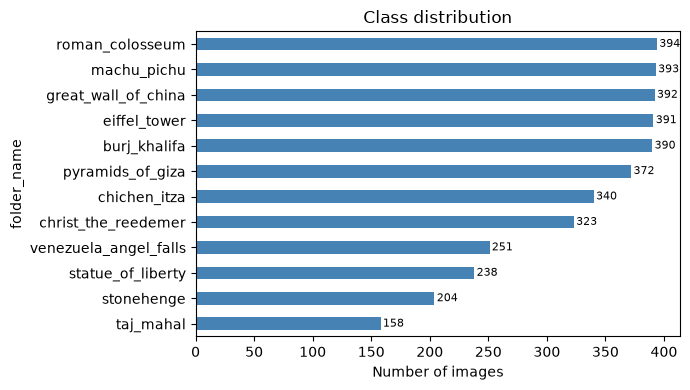

{'train': 2692, 'val': 577, 'test': 577}


In [4]:
# --- class distribution ---
counts = df.folder_name.value_counts().sort_values()
ax = counts.plot.barh(figsize=(7, 4), color="steelblue")
ax.set_xlabel("Number of images"); ax.set_title("Class distribution")
for i, v in enumerate(counts.values): ax.text(v + 2, i, str(v), va="center", fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "class_distribution.png", dpi=200); plt.show()

# --- stratified split ---
train_df, tmp_df = train_test_split(df, test_size=VAL_FRAC + TEST_FRAC, stratify=df.label, random_state=SEED)
val_df, test_df  = train_test_split(tmp_df, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC),
                                    stratify=tmp_df.label, random_state=SEED)
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    d.to_csv(OUT_DIR / f"{name}_split.csv", index=False)
print({k: len(v) for k, v in dict(train=train_df, val=val_df, test=test_df).items()})

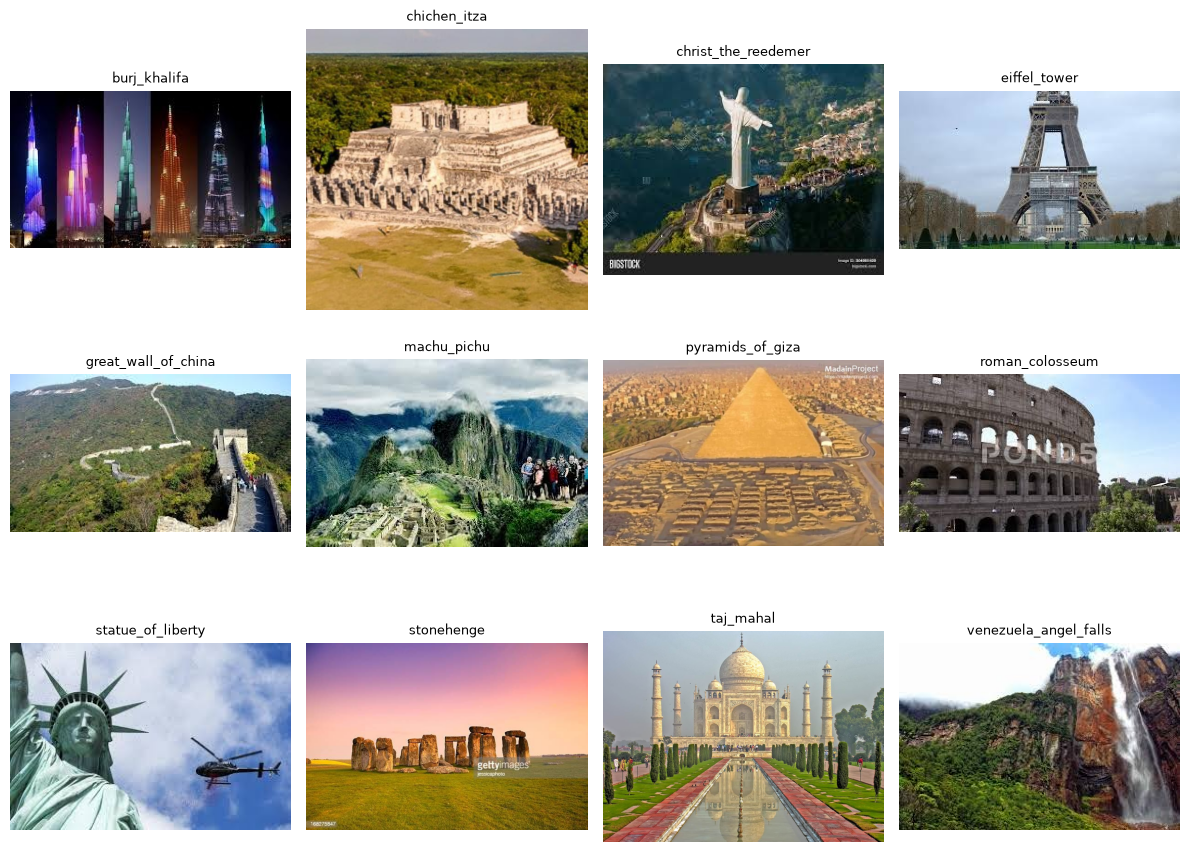

In [5]:
# --- sample images ---
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, c in zip(axes.ravel(), classes):
    r = df[df.folder_name == c].sample(1, random_state=SEED).iloc[0]
    ax.imshow(Image.open(IMG_ROOT / r.folder_name / r.filename).convert("RGB"))
    ax.set_title(c, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.savefig(OUT_DIR / "sample_images.png", dpi=200); plt.show()

## 4. Custom PyTorch `Dataset`

In [6]:
class WondersDataset(Dataset):
    """Loads (image, label) pairs from a dataframe with columns folder_name, filename, label."""
    def __init__(self, frame, root, transform=None):
        self.frame = frame.reset_index(drop=True)
        self.root = Path(root)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        img = Image.open(self.root / row.folder_name / row.filename).convert("RGB")
        if self.transform is not None:
            img = self.transform(img)
        return img, int(row.label)

## 5. Models and `DataLoader`s

Each pretrained model ships with its own preprocessing recipe (`weights.transforms()`): resize/crop size, interpolation, and normalization differ between architectures (this is part of each model's *input requirements*). We therefore build a separate set of `DataLoader`s per model, using that model's own transform. No data augmentation is used because the backbone is frozen and features are extracted once.

In [7]:
MODEL_ZOO = {
    "VGG16":          (models.vgg16,          models.VGG16_Weights.IMAGENET1K_V1),
    "ResNet50":       (models.resnet50,       models.ResNet50_Weights.IMAGENET1K_V2),
    "DenseNet121":    (models.densenet121,    models.DenseNet121_Weights.IMAGENET1K_V1),
    "EfficientNet-B0":(models.efficientnet_b0,models.EfficientNet_B0_Weights.IMAGENET1K_V1),
    "ViT-B/16":       (models.vit_b_16,       models.ViT_B_16_Weights.IMAGENET1K_V1),
}

def strip_classifier(name, model):
    """Remove the final ImageNet layer(s) so the model outputs a feature vector."""
    if name == "VGG16":            model.classifier[6] = nn.Identity()   # 4096-d
    elif name == "ResNet50":       model.fc = nn.Identity()              # 2048-d
    elif name == "DenseNet121":    model.classifier = nn.Identity()      # 1024-d
    elif name == "EfficientNet-B0":model.classifier = nn.Identity()      # 1280-d
    elif name == "ViT-B/16":       model.heads = nn.Identity()           # 768-d
    return model

def make_loaders(transform):
    mk = lambda d, shuffle: DataLoader(WondersDataset(d, IMG_ROOT, transform), batch_size=BATCH_SIZE,
                                       shuffle=shuffle, num_workers=NUM_WORKERS, pin_memory=True,
                                       persistent_workers=NUM_WORKERS > 0)
    # shuffle=False everywhere: features are extracted once, order must match labels
    return mk(train_df, False), mk(val_df, False), mk(test_df, False)

## 6. Feature extraction, head training and evaluation

For each model: (1) extract frozen-backbone features for train/val/test on the GPU, (2) train a 12-way linear head on the training features (best epoch picked by validation accuracy), (3) evaluate on the test set and record accuracy, macro precision/recall/F1, parameter count and GPU inference time per image.

In [8]:
@torch.no_grad()
def extract_features(model, loader):
    model.eval()
    feats, labels, fwd_time = [], [], 0.0
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        torch.cuda.synchronize(); t0 = time.perf_counter()
        with torch.autocast("cuda", dtype=torch.float16):
            f = model(x)
        torch.cuda.synchronize(); fwd_time += time.perf_counter() - t0
        feats.append(f.float().cpu()); labels.append(y)
    return torch.cat(feats), torch.cat(labels), fwd_time

def train_head(Xtr, ytr, Xva, yva, epochs=150, lr=1e-3, wd=1e-4, bs=256):
    """Linear classifier on standardized features; returns best-on-val head + normalization stats."""
    mu, sd = Xtr.mean(0, keepdim=True), Xtr.std(0, keepdim=True) + 1e-6
    Xtr_, Xva_ = ((Xtr - mu) / sd).to(device), ((Xva - mu) / sd).to(device)
    ytr_, yva_ = ytr.to(device), yva.to(device)

    head = nn.Linear(Xtr.shape[1], NUM_CLASSES).to(device)
    cls_w = torch.bincount(ytr, minlength=NUM_CLASSES).float()
    cls_w = (cls_w.sum() / (NUM_CLASSES * cls_w)).to(device)           # inverse-frequency weights
    crit = nn.CrossEntropyLoss(weight=cls_w)
    opt = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    best_acc, best_state = -1, None
    for ep in range(epochs):
        head.train()
        perm = torch.randperm(len(Xtr_), device=device)
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            opt.zero_grad(); loss = crit(head(Xtr_[idx]), ytr_[idx]); loss.backward(); opt.step()
        sched.step()
        head.eval()
        with torch.no_grad():
            acc = (head(Xva_).argmax(1) == yva_).float().mean().item()
        if acc > best_acc:
            best_acc, best_state = acc, {k: v.clone() for k, v in head.state_dict().items()}
    head.load_state_dict(best_state)
    return head.eval(), mu, sd, best_acc

In [9]:
results, preds_store = [], {}

for name, (builder, weights) in MODEL_ZOO.items():
    print(f"\n=== {name} ===")
    model = strip_classifier(name, builder(weights=weights)).to(device)
    n_params = sum(p.numel() for p in builder(weights=None).parameters()) / 1e6   # full ImageNet model size
    for p in model.parameters(): p.requires_grad = False

    tfm = weights.transforms()
    crop = tfm.crop_size[0]; print("input transform:", f"resize={tfm.resize_size[0]}, crop={crop}")
    tr_loader, va_loader, te_loader = make_loaders(tfm)

    t0 = time.time()
    Xtr, ytr, _        = extract_features(model, tr_loader)
    Xva, yva, _        = extract_features(model, va_loader)
    Xte, yte, te_fwd   = extract_features(model, te_loader)
    print(f"features: {tuple(Xtr.shape)} extracted in {time.time()-t0:.0f}s")

    head, mu, sd, val_acc = train_head(Xtr, ytr, Xva, yva)
    with torch.no_grad():
        pred = head(((Xte - mu) / sd).to(device)).argmax(1).cpu().numpy()
    y_true = yte.numpy()

    p, r, f1, _ = precision_recall_fscore_support(y_true, pred, average="macro", zero_division=0)
    results.append({
        "Model": name,
        "Params (M)": round(n_params, 1),
        "Feature dim": Xtr.shape[1],
        "Input crop": f"{crop}x{crop}",
        "Val Acc": round(val_acc, 4),
        "Test Acc": round(accuracy_score(y_true, pred), 4),
        "Precision (macro)": round(p, 4),
        "Recall (macro)": round(r, 4),
        "F1 (macro)": round(f1, 4),
        "GPU ms/img": round(1000 * te_fwd / len(y_true), 2),
    })
    preds_store[name] = (y_true, pred)
    print(results[-1])

    del model, Xtr, Xva, Xte, head
    torch.cuda.empty_cache()


=== VGG16 ===
input transform: resize=256, crop=224
features: (2692, 4096) extracted in 44s
{'Model': 'VGG16', 'Params (M)': 138.4, 'Feature dim': 4096, 'Input crop': '224x224', 'Val Acc': 0.9515, 'Test Acc': 0.9584, 'Precision (macro)': 0.9626, 'Recall (macro)': 0.9592, 'F1 (macro)': 0.9605, 'GPU ms/img': 2.09}

=== ResNet50 ===
input transform: resize=232, crop=224
features: (2692, 2048) extracted in 39s
{'Model': 'ResNet50', 'Params (M)': 25.6, 'Feature dim': 2048, 'Input crop': '224x224', 'Val Acc': 0.9619, 'Test Acc': 0.9844, 'Precision (macro)': 0.9852, 'Recall (macro)': 0.9853, 'F1 (macro)': 0.9851, 'GPU ms/img': 1.14}

=== DenseNet121 ===
input transform: resize=256, crop=224
features: (2692, 1024) extracted in 40s
{'Model': 'DenseNet121', 'Params (M)': 8.0, 'Feature dim': 1024, 'Input crop': '224x224', 'Val Acc': 0.9688, 'Test Acc': 0.9809, 'Precision (macro)': 0.9826, 'Recall (macro)': 0.9783, 'F1 (macro)': 0.9801, 'GPU ms/img': 1.12}

=== EfficientNet-B0 ===
input transform

## 7. Results

In [10]:
res = pd.DataFrame(results).sort_values("F1 (macro)", ascending=False).reset_index(drop=True)
res.to_csv(OUT_DIR / "model_comparison.csv", index=False)
res

,Model,Params (M),Feature dim,Input crop,Val Acc,Test Acc,Precision (macro),Recall (macro),F1 (macro),GPU ms/img
0,ResNet50,25.6,2048,224x224,0.9619,0.9844,0.9852,0.9853,0.9851,1.14
1,EfficientNet-B0,5.3,1280,224x224,0.9636,0.9827,0.9855,0.9850,0.9851,0.87
2,ViT-B/16,86.6,768,224x224,0.9723,0.9809,0.9826,0.9801,0.9808,2.19
3,DenseNet121,8.0,1024,224x224,0.9688,0.9809,0.9826,0.9783,0.9801,1.12
4,VGG16,138.4,4096,224x224,0.9515,0.9584,0.9626,0.9592,0.9605,2.09


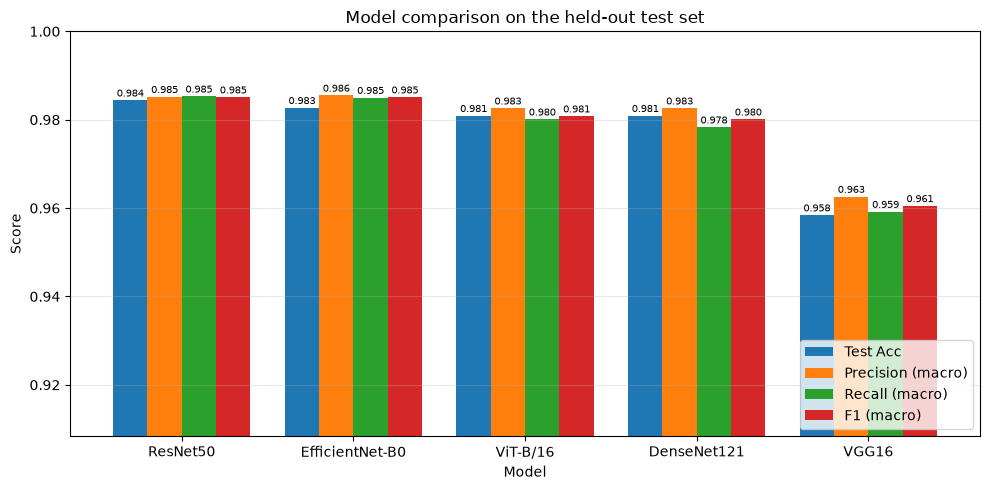

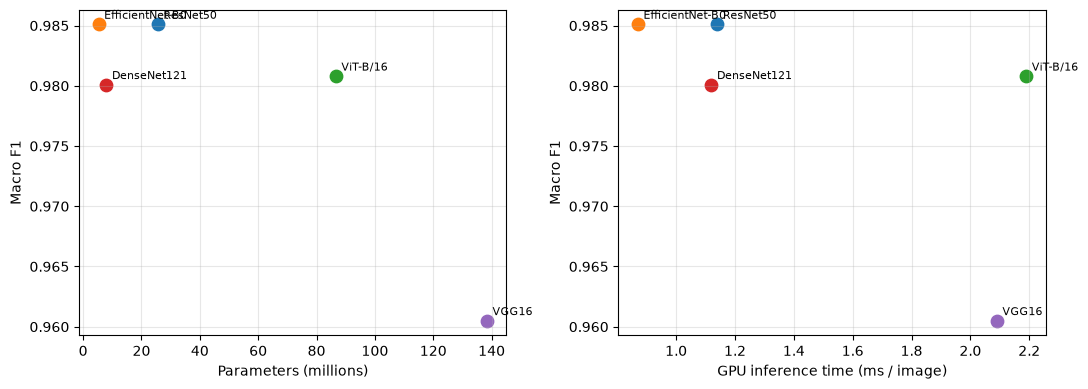

In [11]:
# Grouped bar chart of the four required metrics
metrics = ["Test Acc", "Precision (macro)", "Recall (macro)", "F1 (macro)"]
ax = res.set_index("Model")[metrics].plot.bar(figsize=(10, 5), width=0.8, rot=0)
lo = max(0, res[metrics].min().min() - 0.05)
ax.set_ylim(lo, 1.0); ax.set_ylabel("Score"); ax.set_title("Model comparison on the held-out test set")
ax.legend(loc="lower right"); ax.grid(axis="y", alpha=0.3)
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=7, padding=1)
plt.tight_layout(); plt.savefig(OUT_DIR / "model_comparison.png", dpi=200); plt.show()

# Accuracy vs. model size / speed
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for _, r in res.iterrows():
    ax[0].scatter(r["Params (M)"], r["F1 (macro)"], s=80); ax[0].annotate(r["Model"], (r["Params (M)"], r["F1 (macro)"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax[1].scatter(r["GPU ms/img"], r["F1 (macro)"], s=80);  ax[1].annotate(r["Model"], (r["GPU ms/img"], r["F1 (macro)"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax[0].set_xlabel("Parameters (millions)"); ax[1].set_xlabel("GPU inference time (ms / image)")
for a in ax: a.set_ylabel("Macro F1"); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT_DIR / "f1_vs_complexity.png", dpi=200); plt.show()

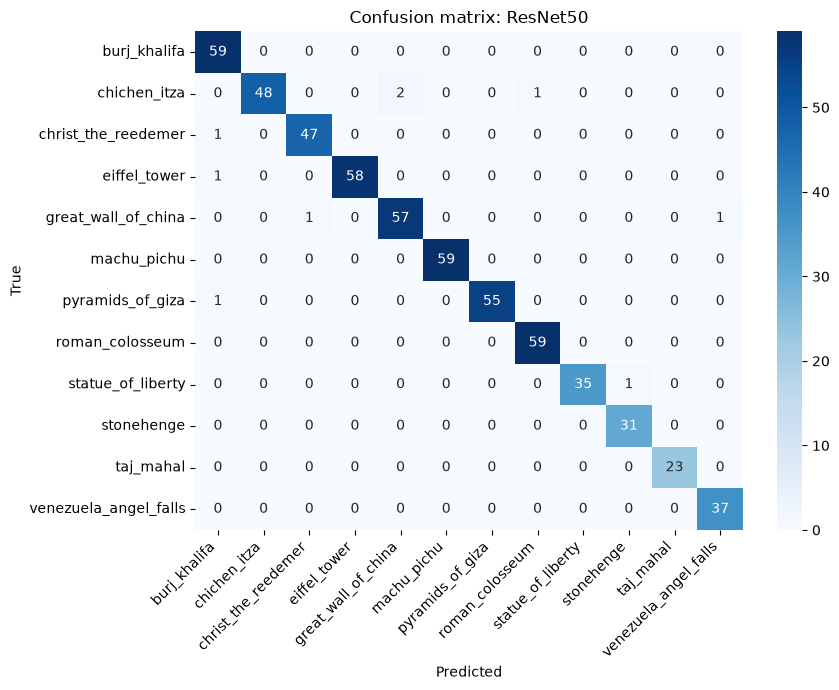

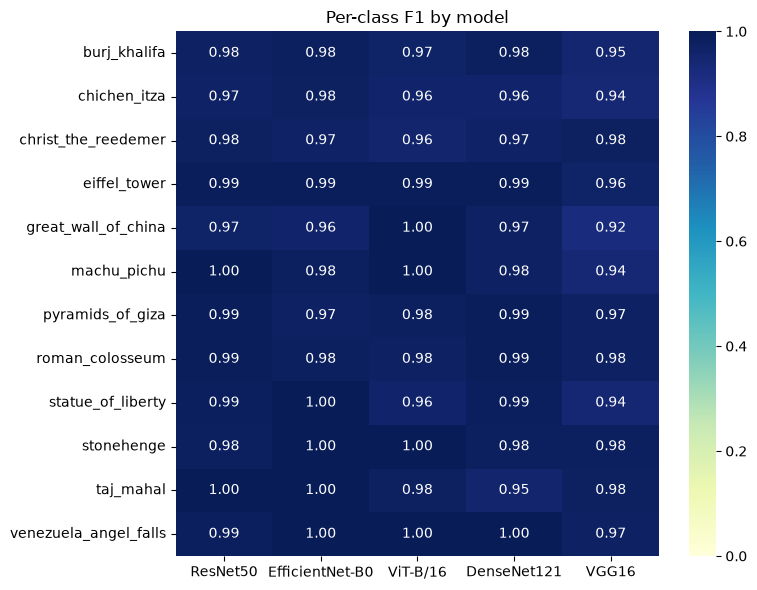

Classification report: ResNet50

                       precision    recall  f1-score   support

         burj_khalifa      0.952     1.000     0.975        59
         chichen_itza      1.000     0.941     0.970        51
  christ_the_reedemer      0.979     0.979     0.979        48
         eiffel_tower      1.000     0.983     0.991        59
  great_wall_of_china      0.966     0.966     0.966        59
          machu_pichu      1.000     1.000     1.000        59
     pyramids_of_giza      1.000     0.982     0.991        56
      roman_colosseum      0.983     1.000     0.992        59
    statue_of_liberty      1.000     0.972     0.986        36
           stonehenge      0.969     1.000     0.984        31
            taj_mahal      1.000     1.000     1.000        23
venezuela_angel_falls      0.974     1.000     0.987        37

             accuracy                          0.984       577
            macro avg      0.985     0.985     0.985       577
         weighted av

In [12]:
# Confusion matrix of the best model + per-class F1 heatmap for all models
best = res.loc[0, "Model"]
y_true, y_pred = preds_store[best]
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"Confusion matrix: {best}")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig(OUT_DIR / "confusion_matrix_best.png", dpi=200); plt.show()

per_class = pd.DataFrame({
    n: precision_recall_fscore_support(*preds_store[n], labels=range(NUM_CLASSES), zero_division=0)[2]
    for n in res.Model}, index=classes)
plt.figure(figsize=(8, 6))
sns.heatmap(per_class, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1)
plt.title("Per-class F1 by model"); plt.tight_layout()
plt.savefig(OUT_DIR / "per_class_f1.png", dpi=200); plt.show()

print(f"Classification report: {best}\n")
print(classification_report(y_true, y_pred, target_names=classes, digits=3))

In [13]:
# Quick facts to quote in the write-up
top, bot = res.iloc[0], res.iloc[-1]
print(f"Best model : {top.Model} (F1={top['F1 (macro)']:.3f}, acc={top['Test Acc']:.3f}, {top['Params (M)']}M params, {top['GPU ms/img']} ms/img)")
print(f"Worst model: {bot.Model} (F1={bot['F1 (macro)']:.3f}, acc={bot['Test Acc']:.3f}, {bot['Params (M)']}M params, {bot['GPU ms/img']} ms/img)")
print(f"F1 spread  : {top['F1 (macro)'] - bot['F1 (macro)']:.3f}")
hard = per_class.mean(1).sort_values().head(3)
print("Hardest classes (mean F1 across models):"); print(hard.round(3).to_string())

Best model : ResNet50 (F1=0.985, acc=0.984, 25.6M params, 1.14 ms/img)
Worst model: VGG16 (F1=0.961, acc=0.958, 138.4M params, 2.09 ms/img)
F1 spread  : 0.025
Hardest classes (mean F1 across models):
chichen_itza           0.962
great_wall_of_china    0.964
christ_the_reedemer    0.971


## 8. Analysis and Conclusion

**Results summary.** All five pretrained backbones transferred well to the 12-class Wonders dataset, with test accuracies between 95.8% and 98.4% on the 577-image test set.

| Model | Params (M) | Test Acc | Precision | Recall | F1 (macro) | GPU ms/img |
|---|---|---|---|---|---|---|
| ResNet50 | 25.6 | 0.9844 | 0.9852 | 0.9853 | 0.9851 | 1.14 |
| EfficientNet-B0 | 5.3 | 0.9827 | 0.9855 | 0.9850 | 0.9851 | 0.87 |
| ViT-B/16 | 86.6 | 0.9809 | 0.9826 | 0.9801 | 0.9808 | 2.19 |
| DenseNet121 | 8.0 | 0.9809 | 0.9826 | 0.9783 | 0.9801 | 1.12 |
| VGG16 | 138.4 | 0.9584 | 0.9626 | 0.9592 | 0.9605 | 2.09 |

ResNet50 and EfficientNet-B0 tie for the best macro F1 (0.985), with ResNet50 having the highest accuracy (98.44%, only 9 misclassified images). VGG16 is clearly the weakest, with 95.84% accuracy and 0.9605 macro F1 (about 24 errors). The best-to-worst spread is 0.025 in F1, about 2.5 percentage points. That is small in absolute terms but meaningful here, since VGG16 makes roughly two and a half times as many errors as the best models. The other four models are within 0.5 points of each other (about 9 to 11 errors each), and with only 577 test images a single image is worth about 0.17 points. Their ranking is therefore not statistically reliable, and I treat them as roughly equivalent.

**Why the models differ.**

1. **Architecture and feature quality.** Because the backbone is frozen, performance depends on how linearly separable the pretrained features are for landmarks. The results match the expectation that architectures with richer feature reuse or global context (ResNet50's residual blocks, DenseNet121's dense connections, ViT's self-attention) beat the plain stack of convolutions in VGG16. The per-class F1 heatmap shows VGG16 was the lowest-scoring model on most classes, with its largest drops on the Great Wall of China (0.92), Chichen Itza, Machu Picchu and the Statue of Liberty (0.94 each). By contrast, ViT-B/16 reached 1.00 F1 on the Great Wall of China, which is consistent with global self-attention helping on scenes where the structure is spread across the image. EfficientNet-B0 also beat VGG16, which suggests careful architecture design matters more than raw depth or width.
2. **Model complexity.** Parameter count did not predict accuracy. VGG16 is the largest model (138.4M parameters, mostly in its fully connected layers) and scored lowest, while EfficientNet-B0 (5.3M) and DenseNet121 (8.0M) matched or beat much larger models. ViT-B/16 (86.6M) did not outperform ResNet50 (25.6M). VGG16's large classifier layers were tuned for ImageNet's 1,000 classes, and its 4096-dimensional features are less discriminative for this task than the more compact features of newer models.
3. **Pretraining recipe.** The torchvision weights were trained with different recipes. ResNet50 uses the improved V2 weights, trained with a more modern recipe than VGG16's original 2014-era weights, which likely contributed to its strong features independent of architecture.
4. **Input requirements.** All models were evaluated at a 224x224 crop, but each uses its own preprocessing (for example, ResNet50 resizes to 232 first and the others to 256). The dataset images are small (median about 300x225 px) and are upsampled, which limits fine detail for all models alike. Since every model used the same crop size, input resolution does not explain the differences between them.
5. **Suitability for this dataset and error analysis.** ImageNet contains many buildings, monuments and outdoor scenes, so transfer to landmarks is favorable, which explains why all models exceeded 95% accuracy. Averaged across the five models, the hardest classes were Chichen Itza (mean F1 0.962), the Great Wall of China (0.964) and Christ the Redeemer (0.971). The ResNet50 confusion matrix shows only 9 errors, so these patterns are indicative rather than conclusive. Two of the three Chichen Itza errors were predicted as the Great Wall of China and one as the Colosseum, and the Great Wall itself was occasionally predicted as Christ the Redeemer or Angel Falls. This is plausible because these classes contain very varied web-scraped scenes (close-ups, crowds, wide landscapes). The Burj Khalifa also acted as a catch-all: single images of Christ the Redeemer, the Eiffel Tower and the Pyramids were predicted as the Burj Khalifa, giving it the lowest precision (0.952) despite perfect recall. Class imbalance did not appear to hurt: the Taj Mahal, the smallest class (23 test images), reached 1.00 F1 with ResNet50 and EfficientNet-B0, which suggests the inverse-frequency class weighting in the training loss was effective. Visually similar stone monuments such as Stonehenge and the Pyramids of Giza were classified very reliably (0.98 to 1.00 F1 for most models).
6. **Speed/efficiency trade-off.** EfficientNet-B0 gives the best accuracy per unit of compute: it is the fastest model (0.87 ms/image on the GPU) while tying for the best F1 with only 5.3M parameters. ResNet50 and DenseNet121 are also fast (about 1.1 ms/image). ViT-B/16 (2.19 ms) and VGG16 (2.09 ms) are about twice as slow, and VGG16 is also the least accurate, so it offers the worst trade-off. For deployment on limited hardware, EfficientNet-B0 is the clear choice. These timings are GPU forward-pass times with fp16 on an RTX 5050 and exclude image loading.

**Conclusion.** ResNet50 and EfficientNet-B0 were the best models, with macro F1 of about 0.985, and VGG16 was the weakest at 0.9605. I would choose EfficientNet-B0, since it matches ResNet50's accuracy at the lowest inference cost and the smallest model size. The remaining errors were concentrated in classes with highly varied imagery (Chichen Itza, the Great Wall of China) rather than in the smallest classes. The main limitations are the frozen feature extractor (only a linear head was trained), a single train/val/test split, a single random seed, and a small test set, which means differences of under about 0.5 points between the top four models should not be over-interpreted. Next steps would be fine-tuning the last blocks of the best backbones, adding data augmentation, inspecting the misclassified images directly, and averaging results over several seeds or cross-validation folds to confirm the ranking.